# Homogenizers: fly's eye lenslet arrays and integrator rods

Lithography steppers, laser line generators, projectors and LED
spotlights all need a field of even irradiance from a source that is
anything but even: an excimer laser with a ragged near field, a Gaussian
beam, an arc, an LED die. Two devices do almost all of this work.

- **Fly's eye (lenslet array) homogenizer:** an array of lenslets cuts
  the beam into many channels, and a condenser overlaps them all in its
  focal plane. With a second array one focal length behind the first (the
  **imaging** homogenizer), each lenslet of the second array images its
  partner in the first onto the field. The field is then a flat top of
  width $W = pF/f$ (pitch $p$, lenslet focal length $f$, condenser $F$),
  whatever the beam looks like.
- **Integrator rod (kaleidoscope):** light focused into a glass rod is
  reflected at its walls. Unfolded, the rod becomes a grid of virtual
  sources (notebook 83, section 6) that overlap at the exit face.

Both work by superposition, so both meet the same enemy: coherence. With
laser light the channels, or the virtual sources, interfere, and the even
field becomes a grid of fringes.

`il.lenslet_array()` and `il.thin_lens()` trace rays through ideal thin
lenslets and lenses (with `il.propagate()` between them, and
`il.light_pipe()` for the rod), and `il.fly_eye_field_1d()` computes the
scalar wave field of a fly's eye in the focal plane of its condenser. The
sections: the field from a Gaussian and from a ragged beam (1), how many
channels it takes (2), imaging against non-imaging homogenizers under
divergent and tilted input (3), coherent light and how partial coherence
washes the interference out (4), and the rod (5).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import illumination as il
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(86)

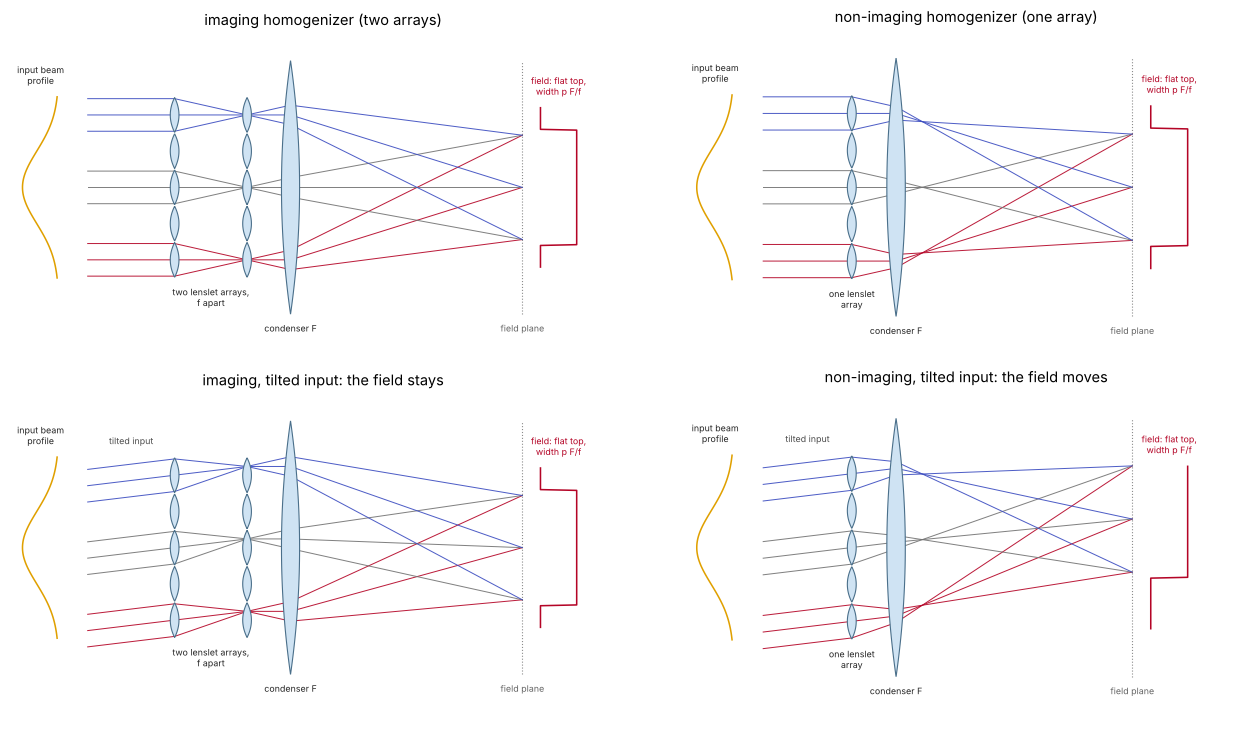

In [2]:
fig, ax = plt.subplots(2, 2, figsize=(16, 9), layout="constrained")
sketch.fly_eye_homogenizer(ax[0, 0], imaging=True, title="imaging homogenizer (two arrays)")
sketch.fly_eye_homogenizer(ax[0, 1], imaging=False, title="non-imaging homogenizer (one array)")
sketch.fly_eye_homogenizer(ax[1, 0], imaging=True, tilt=0.12, title="imaging, tilted input: the field stays")
sketch.fly_eye_homogenizer(ax[1, 1], imaging=False, tilt=0.12, title="non-imaging, tilted input: the field moves")
plt.show()

## 1. A flat top from any beam

The design: 15 × 15 lenslets with $p = 0.5$ mm and $f = 5$ mm in two
arrays $f$ apart, and a condenser with $F = 100$ mm, so $W = 10$ mm. We
trace a million rays of two collimated beams:

- a Gaussian beam with $\sigma = 1.5$ mm;
- a ragged beam: a flat part with a 2:1 intensity gradient and an
  off-centre hot spot carrying a quarter of the power.

Each ray is refracted by the lenslet it meets in the first array, focused
into its partner in the second, and sent by the condenser to the field
position $u = -F(x - c)/f$, where $c$ is the lenslet centre.

In [3]:
P_L, F_L, N_L, F_C = 0.5, 5.0, 15, 100.0          # lenslet pitch, focal length, number per side, condenser
W_FIELD = P_L*F_C/F_L                            # 10 mm flat top

def homogenize(P, d, imaging=True, pitch=P_L, f=F_L, n_l=N_L, F=F_C):
    """Rays through one or two lenslet arrays and the condenser; points in its focal plane."""
    d1, _ = il.lenslet_array(P, d, pitch, f, n_lenslets=n_l)
    if imaging:
        P2 = il.propagate(P, d1, f)
        d2, _ = il.lenslet_array(P2, d1, pitch, f, n_lenslets=n_l)
    else:
        P2, d2 = P, d1
    d3 = il.thin_lens(P2, d2, F)
    return il.propagate(P2, d3, F)

def beam(n, kind, divergence=0.0, tilt=0.0):
    """Collimated input beams: a Gaussian (sigma 1.5 mm) or a messy beam with a hot spot."""
    if kind == "gauss":
        x, y = rng.normal(0, 1.5, n), rng.normal(0, 1.5, n)
    else:
        # a flat-ish beam with a gradient and an off-centre hot spot: a typical excimer or LED near field
        m = rng.random(n) < 0.25
        x = np.where(m, rng.normal(1.6, 0.4, n), rng.uniform(-3.2, 3.2, n))
        y = np.where(m, rng.normal(-1.0, 0.4, n), rng.uniform(-2.6, 2.6, n))
        keep = rng.random(n) < np.where(m, 1.0, 0.55 + 0.45*(x + 3.2)/6.4)
        x, y = x[keep], y[keep]
    P = np.column_stack([x, y, 0*x])
    tx = tilt + divergence*rng.standard_normal(len(x))
    ty = divergence*rng.standard_normal(len(x))
    d = np.column_stack([tx, ty, np.ones_like(tx)])
    return P, d/np.linalg.norm(d, axis=1)[:, None]

def uniformity(Q, half=0.8*W_FIELD/2, bins=40):
    """rms/mean of the irradiance in the central part of the field (2D histogram)."""
    H, _, _ = np.histogram2d(Q[:, 0], Q[:, 1], bins=bins, range=[(-half, half)]*2)
    return H.std()/H.mean()

N1 = 1_000_000
maps = {}
for kind in ("gauss", "messy"):
    P, d = beam(N1, kind)
    Q = homogenize(P, d)
    ok = np.isfinite(Q[:, 0])
    maps[kind] = (P, Q[ok])
    print("{:6s}: transmitted {:.3f}, field width {:.2f} mm (p F/f = {:.1f}), "
          "rms/mean over the central 80 %: {:.1%} (shot noise {:.1%})"
          .format(kind, ok.mean(), np.ptp(Q[ok, 0]), W_FIELD, uniformity(Q[ok]),
                  1/np.sqrt(ok.sum()/40**2)))

gauss : transmitted 0.975, field width 10.00 mm (p F/f = 10.0), rms/mean over the central 80 %: 5.0% (shot noise 4.1%)


messy : transmitted 1.000, field width 10.00 mm (p F/f = 10.0), rms/mean over the central 80 %: 6.4% (shot noise 4.4%)


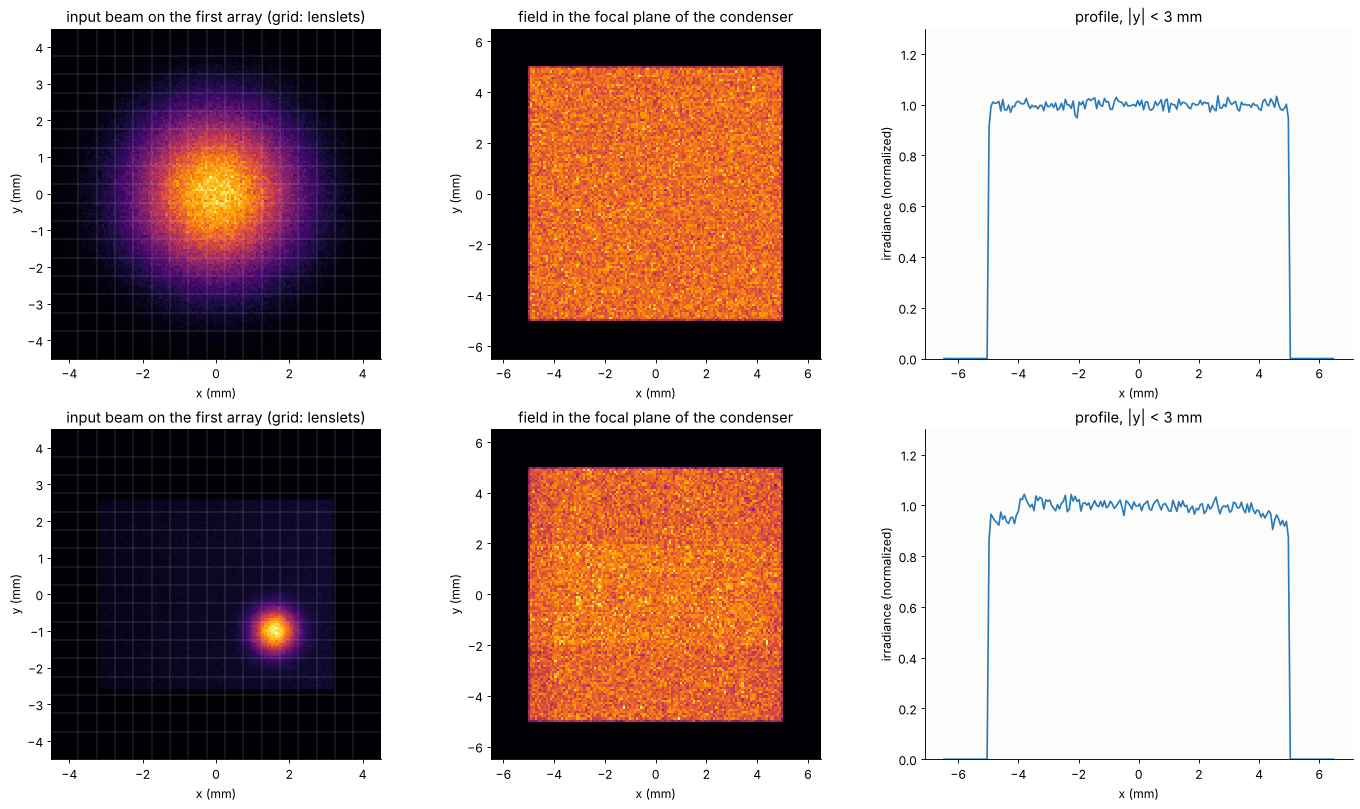

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(17, 10), layout="constrained")
for row, kind in enumerate(("gauss", "messy")):
    P, Q = maps[kind]
    ax[row, 0].hist2d(P[:, 0], P[:, 1], bins=150, range=[(-4.5, 4.5)]*2, cmap="inferno")
    for k in range(N_L + 1):
        e = (k - N_L/2)*P_L
        ax[row, 0].axvline(e, color="w", lw=0.3, alpha=0.5)
        ax[row, 0].axhline(e, color="w", lw=0.3, alpha=0.5)
    ax[row, 0].set_title("input beam on the first array (grid: lenslets)")
    ax[row, 1].hist2d(Q[:, 0], Q[:, 1], bins=150, range=[(-6.5, 6.5)]*2, cmap="inferno")
    ax[row, 1].set_title("field in the focal plane of the condenser")
    for a in ax[row, :2]:
        a.set_xlabel("x (mm)")
        a.set_ylabel("y (mm)")
        a.set_aspect("equal")
    h, e = np.histogram(Q[np.abs(Q[:, 1]) < 3, 0], bins=200, range=(-6.5, 6.5))
    ax[row, 2].plot(0.5*(e[1:] + e[:-1]), h/h[np.abs(0.5*(e[1:] + e[:-1])) < 4].mean(), color=BLUE)
    ax[row, 2].set_ylim(0, 1.3)
    ax[row, 2].set_xlabel("x (mm)")
    ax[row, 2].set_ylabel("irradiance (normalized)")
    ax[row, 2].set_title("profile, |y| < 3 mm")
plt.show()

Both beams become the same 10 mm square. The rms variation over the
central 80 %, 5.0 % and 6.4 %, is mostly the shot noise of the histogram
(4.1 % and 4.4 %). The ragged beam leaves a little more, because its hot
spot (0.4 mm rms) is about as large as a lenslet, and the field shows what
falls inside each lenslet. Edge to edge the field is exactly
$pF/f = 10$ mm. The 2.5 % of the Gaussian that misses the 7.5 mm array is
lost.

## 2. How many channels?

The field is the sum of the input profile over all lenslets,
$E(u) = \sum_c I(c - fu/F)$: a periodic sum of the beam. We vary the pitch
from 3 mm to 0.15 mm and keep the field at 10 mm ($f = pF/W$). Two beams
are compared:

- **a smooth Gaussian:** by Poisson's summation formula the periodic sum
  has the first Fourier component $\hat I(1/p)$, so the rms is
  $\sqrt 2\,e^{-2\pi^2\sigma^2/p^2}$.
- **the same Gaussian with 30 % rms fine structure** (correlation length
  50 µm, standing in for the speckled near field of a real laser): $N$
  independent channels average the structure down as
  $0.3/\sqrt{N_\text{eff}}$. Here $N_\text{eff} = (\sum w)^2/\sum w^2$
  counts the lenslets weighted by the light they carry.

In [5]:
# uniformity against the number of lenslets across the beam, field width fixed (f = p F/W).
# Each channel images its lenslet aperture onto the field: E(u) = sum over lenslet centres c of I(c - f u/F).
xf = np.arange(-8, 8, 0.002)
env = np.exp(-xf**2/(2*1.5**2))                  # sigma = 1.5 mm intensity envelope
ELL = 0.05                                       # correlation length of the fine structure (mm)
kern = np.exp(-np.arange(-0.3, 0.3, 0.002)**2/(2*ELL**2))
def structured():
    g = np.convolve(rng.standard_normal(len(xf)), kern/np.sqrt(np.sum(kern**2)), mode="same")
    return env*np.clip(1 + 0.3*g, 0, None)       # 30 % rms fine structure on the Gaussian
beams = [structured() for _ in range(8)]
pitches = np.array([3.0, 2.0, 1.5, 1.0, 0.75, 0.5, 0.3, 0.2, 0.15])
us = np.linspace(-0.4, 0.4, 2001)*W_FIELD           # central 80 % of the field
smooth, struct, N_eff = [], [], []
for p in pitches:
    f = p*F_C/W_FIELD
    n_l = int(np.ceil(12/p)) | 1
    c = (np.arange(n_l) - (n_l - 1)/2)*p
    field = lambda I: sum(np.interp(cc - f*us/F_C, xf, I) for cc in c)
    E = field(env)
    smooth.append(E.std()/E.mean())
    struct.append(np.mean([E.std()/E.mean() for E in map(field, beams)]))
    w = np.exp(-c**2/(2*1.5**2))
    N_eff.append(np.sum(w)**2/np.sum(w**2))      # channels weighted by the light they carry
smooth, struct, N_eff = map(np.array, (smooth, struct, N_eff))
pred_smooth = np.sqrt(2)*np.exp(-2*np.pi**2*1.5**2/pitches**2)    # first Fourier term of the periodic sum
for p, a1, ps, a2, ne in zip(pitches, smooth, pred_smooth, struct, N_eff):
    print("pitch {:.2f} mm, N_eff {:5.1f}: smooth {:.1e} (sqrt2 exp(-2 pi^2 sigma^2/p^2) = {:.1e}), structured {:.3f} (0.3/sqrt(N_eff) = {:.3f})"
          .format(p, ne, a1, ps, a2, 0.3/np.sqrt(ne)))

pitch 3.00 mm, N_eff   1.6: smooth 8.5e-03 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 1.0e-02), structured 0.229 (0.3/sqrt(N_eff) = 0.240)
pitch 2.00 mm, N_eff   2.6: smooth 1.9e-05 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 2.1e-05), structured 0.178 (0.3/sqrt(N_eff) = 0.185)
pitch 1.50 mm, N_eff   3.5: smooth 2.1e-06 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 3.8e-09), structured 0.142 (0.3/sqrt(N_eff) = 0.159)
pitch 1.00 mm, N_eff   5.3: smooth 2.5e-06 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 7.3e-20), structured 0.128 (0.3/sqrt(N_eff) = 0.130)
pitch 0.75 mm, N_eff   7.1: smooth 2.2e-06 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 7.2e-35), structured 0.107 (0.3/sqrt(N_eff) = 0.113)
pitch 0.50 mm, N_eff  10.6: smooth 1.4e-06 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 9.9e-78), structured 0.080 (0.3/sqrt(N_eff) = 0.092)
pitch 0.30 mm, N_eff  17.7: smooth 6.9e-07 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 6.8e-215), structured 0.031 (0.3/sqrt(N_eff) = 0.071)
pitch 0.20 mm, N_eff  26.6: smooth 3.5e-07 (sqrt2 exp(-2 pi^2 sigma^2/p^2) = 0.0e+00), st

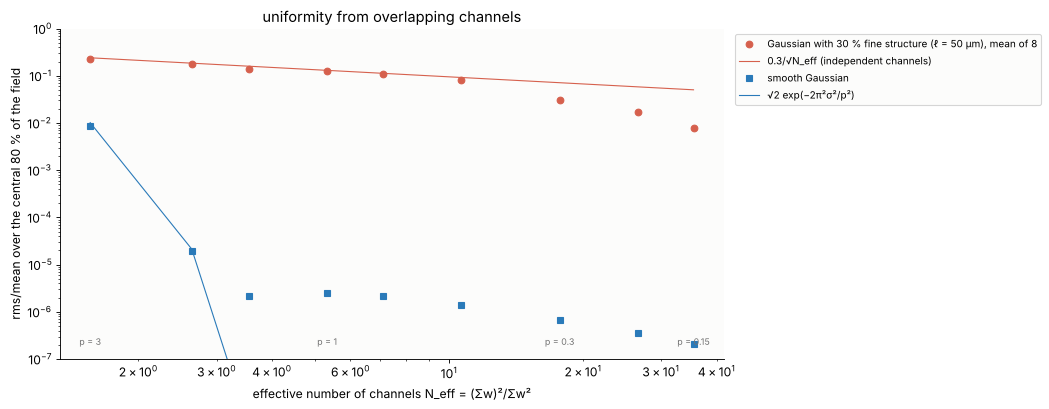

In [6]:
fig, ax = plt.subplots(figsize=(13, 5), layout="constrained")
ax.loglog(N_eff, struct, "o", color=RED, label="Gaussian with 30 % fine structure (ℓ = 50 µm), mean of 8")
ax.loglog(N_eff, 0.3/np.sqrt(N_eff), "-", color=RED, lw=1, label="0.3/√N_eff (independent channels)")
ax.loglog(N_eff, smooth, "s", color=BLUE, label="smooth Gaussian")
ax.loglog(N_eff, pred_smooth, "-", color=BLUE, lw=1, label="√2 exp(−2π²σ²/p²)")
for p, ne in zip(pitches[[0, 3, 6, 8]], N_eff[[0, 3, 6, 8]]):
    ax.annotate("p = {:g}".format(p), (ne, 2e-7), fontsize=8, ha="center", color=GREY)
ax.set_ylim(1e-7, 1)
ax.set_xlabel("effective number of channels N_eff = (Σw)²/Σw²")
ax.set_ylabel("rms/mean over the central 80 % of the field")
ax.set_title("uniformity from overlapping channels")
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

A smooth beam needs very few channels: two lenslets across the beam give
$10^{-2}$, three give $2\times 10^{-5}$, as the Fourier estimate says.
Below that the curve levels off near $10^{-6}$, the limit of this
calculation. Fine structure is what limits real homogenizers. It averages
only as $1/\sqrt{N_\text{eff}}$, until the pitch approaches a few
correlation lengths (0.3 mm and below). Then each lenslet sees an
almost even piece of the beam, and the field improves faster than the
estimate.

## 3. Imaging or non-imaging: divergence and tilt

With one array (the **non-imaging** homogenizer) the condenser maps
directions: a ray leaves lenslet $c$ with the tangent
$\theta - (x - c)/f$ and lands at $u = F\theta - F(x - c)/f$. A beam
divergence blurs the edges of the field by $F$ times the divergence, and a
tilt moves the whole field. With the second array, the ray crosses it at
$c + f\theta$ and leaves with the tangent $-(x - c)/f$: the tilt drops
out. This holds as long as the focus stays inside the partner lenslet,
$|\theta| < p/2f$. Beyond that, the light crosses into the neighbouring
channel, and a ghost field appears one field width away (crosstalk).
The two cases traced:

- collimated beams with 0, 2 and 5 mrad rms divergence;
- a beam with 10 mrad divergence tilted up to 0.09 rad.

In [7]:
divs = [0.0, 0.002, 0.005]
prof = {}
edges = np.linspace(-7, 7, 281)
for imaging in (True, False):
    for dv in divs:
        P, d = beam(400_000, "gauss", divergence=dv)
        Q = homogenize(P, d, imaging=imaging)
        q = Q[np.isfinite(Q[:, 0]) & (np.abs(Q[:, 1]) < 3), 0]
        prof[imaging, dv] = np.histogram(q, bins=edges)[0]
tilts = np.linspace(0, 0.09, 19)
tilt_res = []
for imaging in (True, False):
    for t in tilts:
        P, d = beam(200_000, "gauss", divergence=0.01, tilt=t)
        Q = homogenize(P, d, imaging=imaging)
        q = Q[np.isfinite(Q[:, 0]), 0]
        inside = np.mean(np.abs(q) <= W_FIELD/2)
        tilt_res.append((imaging, t, np.median(q), inside))
tilt_res = np.array(tilt_res, dtype=float)
acc = P_L/(2*F_L)
print("acceptance of the imaging homogenizer: p/2f = {:.3f} rad".format(acc))
for imaging, t, med, inside in tilt_res[::3]:
    print("{:12s} tilt {:.3f}: field centre {:+.2f} mm (F tilt = {:.2f}), fraction inside the nominal field {:.3f}"
          .format("imaging" if imaging else "non-imaging", t, med, F_C*t, inside))

acceptance of the imaging homogenizer: p/2f = 0.050 rad
imaging      tilt 0.000: field centre -0.01 mm (F tilt = 0.00), fraction inside the nominal field 1.000
imaging      tilt 0.015: field centre +0.00 mm (F tilt = 1.50), fraction inside the nominal field 1.000
imaging      tilt 0.030: field centre +0.11 mm (F tilt = 3.00), fraction inside the nominal field 0.977
imaging      tilt 0.045: field centre +2.24 mm (F tilt = 4.50), fraction inside the nominal field 0.691
imaging      tilt 0.060: field centre +9.04 mm (F tilt = 6.00), fraction inside the nominal field 0.160
imaging      tilt 0.075: field centre +9.96 mm (F tilt = 7.50), fraction inside the nominal field 0.006
imaging      tilt 0.090: field centre +9.98 mm (F tilt = 9.00), fraction inside the nominal field 0.000
non-imaging  tilt 0.010: field centre +0.99 mm (F tilt = 1.00), fraction inside the nominal field 0.882
non-imaging  tilt 0.025: field centre +2.50 mm (F tilt = 2.50), fraction inside the nominal field 0.750
non-imag

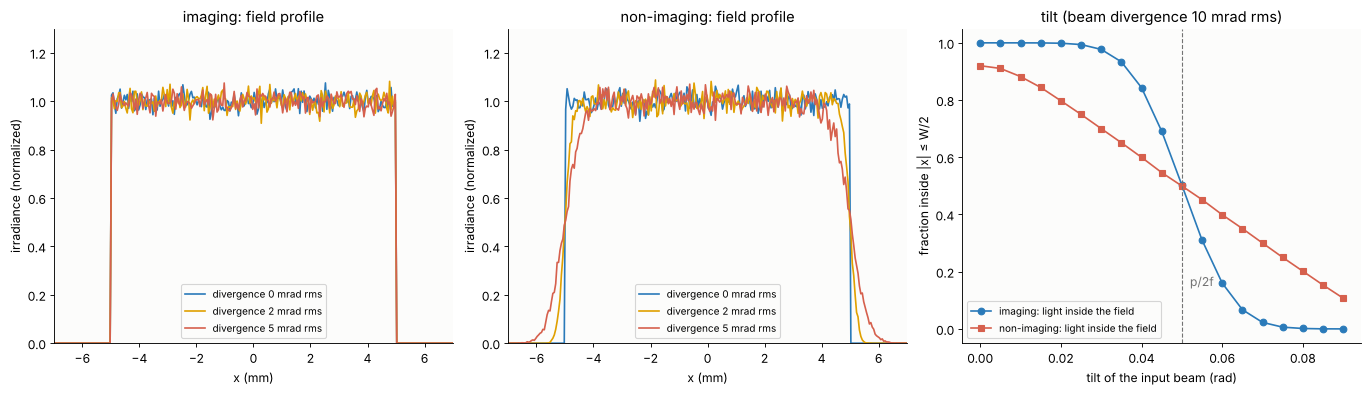

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
xc = 0.5*(edges[1:] + edges[:-1])
for a, imaging in zip(ax[:2], (True, False)):
    for dv, c in zip(divs, (BLUE, ORANGE, RED)):
        h = prof[imaging, dv]
        a.plot(xc, h/h[np.abs(xc) < 3].mean(), color=c, label="divergence {:.0f} mrad rms".format(1e3*dv))
    a.set_xlim(-7, 7)
    a.set_ylim(0, 1.3)
    a.set_xlabel("x (mm)")
    a.set_ylabel("irradiance (normalized)")
    a.set_title(("imaging" if imaging else "non-imaging") + ": field profile")
    a.legend(loc="lower center", fontsize=9)
for imaging, c, m in ((True, BLUE, "o"), (False, RED, "s")):
    r = tilt_res[tilt_res[:, 0] == imaging]
    ax[2].plot(r[:, 1], r[:, 3], m + "-", color=c, label="{}: light inside the field".format("imaging" if imaging else "non-imaging"))
ax[2].axvline(acc, color=GREY, ls="--", lw=1)
ax[2].text(acc + 0.002, 0.15, "p/2f", color=GREY)
ax[2].set_xlabel("tilt of the input beam (rad)")
ax[2].set_ylabel("fraction inside |x| ≤ W/2")
ax[2].set_title("tilt (beam divergence 10 mrad rms)")
ax[2].legend(fontsize=9)
plt.show()

The imaging homogenizer keeps its sharp 10 mm edges at every divergence.
The non-imaging one blurs them by about $F\sigma_\theta = 0.5$ mm at
5 mrad. Under tilt, the non-imaging field moves by exactly $F\theta$, and
the light inside the nominal field falls linearly. Its 0.92 at zero tilt
is the 10 mrad divergence spilling over the edges. The imaging
homogenizer holds the field in place up to about 0.03 rad. Then the
divergent beam starts to cross into the neighbouring channels, and at
$p/2f = 0.05$ rad half the light goes into the ghost. This acceptance
angle is the homogenizer's étendue: an imaging fly's eye accepts
$W_\text{array}\cdot 2\cdot p/2f$ per dimension, and any source within
that is homogenized without loss.

## 4. Coherent light: the channels interfere

For a laser beam the channels are mutually coherent. The field in the
focal plane of the condenser is then the Fourier transform of a periodic
field, whose period is the pitch. It is a comb of bright lines with the
period $\lambda F/p$ (0.1 mm for 500 nm), under the flat-top envelope.
`il.fly_eye_field_1d()` computes it with the exact angular spectrum
between the arrays.

Partial spatial coherence helps. A source with a range of directions of
full width $\Delta\theta$ (uniform) shifts the comb by $F\theta$ for each
direction while the envelope stays put (section 3). The modulation at the
period $\lambda F/p$ is then multiplied by
$|\operatorname{sinc}(\Delta\theta\,p/\lambda)|$. We add the intensities
of 81 tilted plane waves.

In [9]:
WL = 0.5e-3
NX = 2**15
x = np.linspace(-12, 12, NX, endpoint=False)
E0 = np.exp(-x**2/(2*(2*1.5)**2))                 # amplitude of the sigma = 1.5 mm intensity profile
u, U = il.fly_eye_field_1d(E0, x, WL, P_L, F_L, F_L, focal_length=F_C, n_lenslets=N_L)
I_coh = np.abs(U)**2
period = WL*F_C/P_L
central = np.abs(u) < 0.4*W_FIELD
print("coherent: interference period lambda F/p = {:.3f} mm, rms/mean {:.2f}".format(period, I_coh[central].std()/I_coh[central].mean()))
# partially coherent illumination: plane waves with tilts spread uniformly over a full angle D
def averaged(D, n_t=81):
    I = 0.0
    for th in np.linspace(-D/2, D/2, n_t):
        _, Ut = il.fly_eye_field_1d(E0*np.exp(1j*2*np.pi/WL*np.sin(th)*x), x, WL, P_L, F_L, F_L,
                                    focal_length=F_C, n_lenslets=N_L)
        I = I + np.abs(Ut)**2
    return I/n_t
spreads = np.array([0.0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0])*WL/P_L
contrast = []
I_part = {}
for D in spreads:
    I = averaged(D) if D > 0 else I_coh
    I_part[D] = I
    # contrast of the comb: amplitude of the Fourier component at lambda F/p relative to the mean
    c = I[central]
    comp = np.abs(np.mean(c*np.exp(-2j*np.pi*u[central]/period)))
    contrast.append(2*comp/c.mean())
contrast = np.array(contrast)
for D, c in zip(spreads, contrast):
    print("tilt spread {:.2f} lambda/p: comb modulation {:.3f}, |sinc| {:.3f}".format(D*P_L/WL, c, contrast[0]*abs(np.sinc(D*P_L/WL))))

coherent: interference period lambda F/p = 0.100 mm, rms/mean 3.04


tilt spread 0.00 lambda/p: comb modulation 1.939, |sinc| 1.939
tilt spread 0.25 lambda/p: comb modulation 1.741, |sinc| 1.746
tilt spread 0.50 lambda/p: comb modulation 1.219, |sinc| 1.234
tilt spread 0.75 lambda/p: comb modulation 0.557, |sinc| 0.582
tilt spread 1.00 lambda/p: comb modulation 0.024, |sinc| 0.000
tilt spread 1.50 lambda/p: comb modulation 0.406, |sinc| 0.411
tilt spread 2.00 lambda/p: comb modulation 0.023, |sinc| 0.000
tilt spread 3.00 lambda/p: comb modulation 0.024, |sinc| 0.000


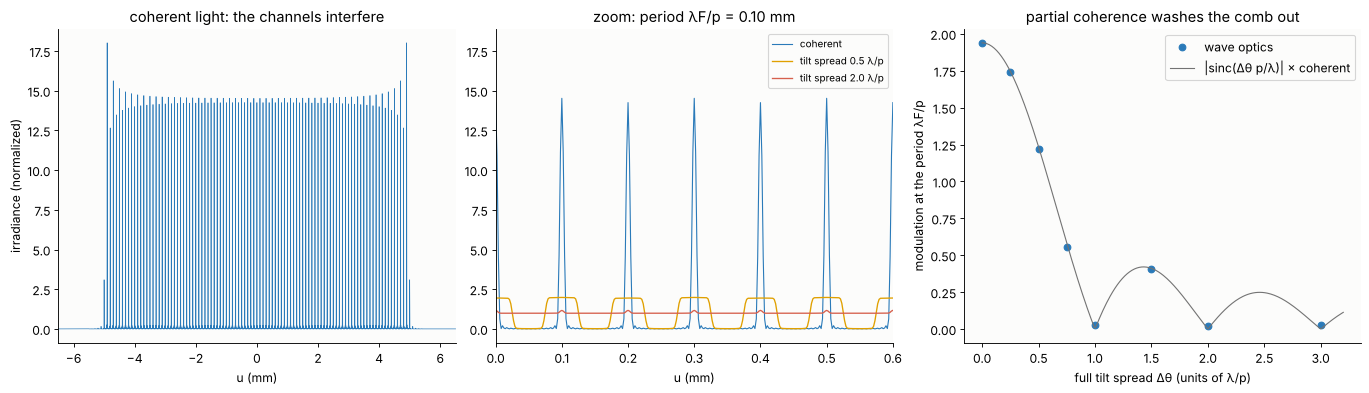

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), layout="constrained")
ax[0].plot(u, I_coh/I_coh[central].mean(), color=BLUE, lw=0.6)
ax[0].set_xlim(-6.5, 6.5)
ax[0].set_xlabel("u (mm)")
ax[0].set_ylabel("irradiance (normalized)")
ax[0].set_title("coherent light: the channels interfere")
ax[1].plot(u, I_coh/I_coh[central].mean(), color=BLUE, lw=1, label="coherent")
for D, c in ((0.5*WL/P_L, ORANGE), (2*WL/P_L, RED)):
    ax[1].plot(u, I_part[D]/I_part[D][central].mean(), color=c, lw=1.2, label="tilt spread {:.1f} λ/p".format(D*P_L/WL))
ax[1].set_xlim(0, 0.6)
ax[1].set_xlabel("u (mm)")
ax[1].set_title("zoom: period λF/p = {:.2f} mm".format(period))
ax[1].legend(fontsize=9)
ss = np.linspace(0, 3.2, 300)
ax[2].plot(spreads*P_L/WL, contrast, "o", color=BLUE, label="wave optics")
ax[2].plot(ss, contrast[0]*np.abs(np.sinc(ss)), color=GREY, lw=1, label="|sinc(Δθ p/λ)| × coherent")
ax[2].set_xlabel("full tilt spread Δθ (units of λ/p)")
ax[2].set_ylabel("modulation at the period λF/p")
ax[2].set_title("partial coherence washes the comb out")
ax[2].legend()
plt.show()

The coherent field is a set of narrow lines, one per period, each as
wide as the period divided by the number of lenslets (15), with an rms
three times the mean. The modulation follows the sinc to 0.02. It
vanishes at $\Delta\theta = \lambda/p$, $2\lambda/p$, ..., where the
tilts shift the comb by whole periods, and comes back at $1.5\,\lambda/p$
with 21 % of its coherent value. At $2\lambda/p$ the field is flat again.
So a fly's eye needs a source with an angular spread of at least
$\lambda/p$ per lenslet, roughly as many independent modes across the
array as there are lenslets. Excimer lasers have hundreds of transverse
modes, which is why they work with fly's eyes. A single-mode laser needs
a moving diffuser, a delay staircase or a rotating mirror to add the
diversity. Speckle reduction is the subject of the next notebook.

## 5. The integrator rod

The rod of notebook 83: a square glass rod, $W = 2$ mm and $n = 1.5$. A
spot of 0.1 mm rms is focused on the centre of its entrance with
NA 0.3, and we trace 400,000 rays through rods of increasing length
(`il.light_pipe()`, by unfolding). Inside the glass the marginal ray has
$\tan\theta = 0.2$, so it is reflected $L\tan\theta/W$ times per wall,
once every 10 mm.

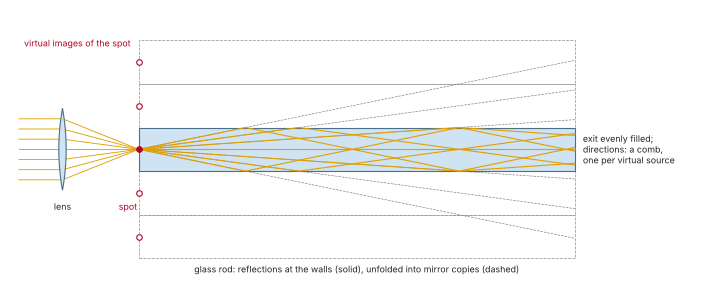

In [11]:
fig, ax = plt.subplots(figsize=(13, 4.6))
sketch.light_pipe_images(ax)
plt.show()

In [12]:
W_ROD, N_ROD, NA_IN = 2.0, 1.5, 0.3
lengths = np.array([5, 10, 20, 30, 40, 60, 80, 120])
N5 = 400_000
P5 = np.column_stack([rng.normal(0, 0.05, N5), rng.normal(0, 0.05, N5), np.zeros(N5)])   # a focused spot
d5 = il.lambertian_directions(N5, NA_IN, rng=rng)
rod_uni, rod_maps = [], {}
for L in lengths:
    Po, do, k = il.light_pipe(P5, d5, W_ROD, L, n_pipe=N_ROD)
    ok = np.isfinite(Po[:, 0])
    H, _, _ = np.histogram2d(Po[ok, 0], Po[ok, 1], bins=20, range=[(-1, 1)]*2)
    rod_uni.append(H.std()/H.mean())
    if L in (10, 30, 120):
        rod_maps[L] = Po[ok]
    print("rod {:3d} mm: reflections per wall up to {:.1f}, rms/mean of the exit face {:.1%} (shot noise {:.1%})"
          .format(L, L*np.tan(np.arcsin(NA_IN/N_ROD))/W_ROD, H.std()/H.mean(), 1/np.sqrt(ok.sum()/400)))
rod_uni = np.array(rod_uni)
# coherent light: the exit field is the sum of spherical waves from the virtual sources
x5 = np.linspace(-1, 1, 4001)
def rod_coherent(L, x_src=0.0, n_m=40):
    k = 2*np.pi/WL*N_ROD
    t_max = np.tan(np.arcsin(NA_IN/N_ROD))
    E = 0
    for m in range(-n_m, n_m + 1):
        xm = m*W_ROD + (-1)**m*x_src
        r = np.sqrt((x5 - xm)**2 + L**2)
        E = E + np.where(np.abs(x5 - xm) <= t_max*L, np.exp(1j*k*r)/np.sqrt(r), 0)
    return np.abs(E)**2
I_rod = rod_coherent(60.0)
I_rod_ext = np.mean([rod_coherent(60.0, xs_) for xs_ in np.linspace(-0.1, 0.1, 41)], axis=0)
for name, I in (("point source", I_rod), ("0.2 mm incoherent source", I_rod_ext)):
    c = np.abs(x5) < 0.8
    print("coherent rod, 60 mm, {}: rms/mean {:.2f}".format(name, I[c].std()/I[c].mean()))

rod   5 mm: reflections per wall up to 0.5, rms/mean of the exit face 43.1% (shot noise 3.2%)
rod  10 mm: reflections per wall up to 1.0, rms/mean of the exit face 17.4% (shot noise 3.2%)


rod  20 mm: reflections per wall up to 2.0, rms/mean of the exit face 6.4% (shot noise 3.2%)
rod  30 mm: reflections per wall up to 3.1, rms/mean of the exit face 4.2% (shot noise 3.2%)


rod  40 mm: reflections per wall up to 4.1, rms/mean of the exit face 3.5% (shot noise 3.2%)
rod  60 mm: reflections per wall up to 6.1, rms/mean of the exit face 3.2% (shot noise 3.2%)


rod  80 mm: reflections per wall up to 8.2, rms/mean of the exit face 3.4% (shot noise 3.2%)
rod 120 mm: reflections per wall up to 12.2, rms/mean of the exit face 3.3% (shot noise 3.2%)


coherent rod, 60 mm, point source: rms/mean 0.80
coherent rod, 60 mm, 0.2 mm incoherent source: rms/mean 0.24


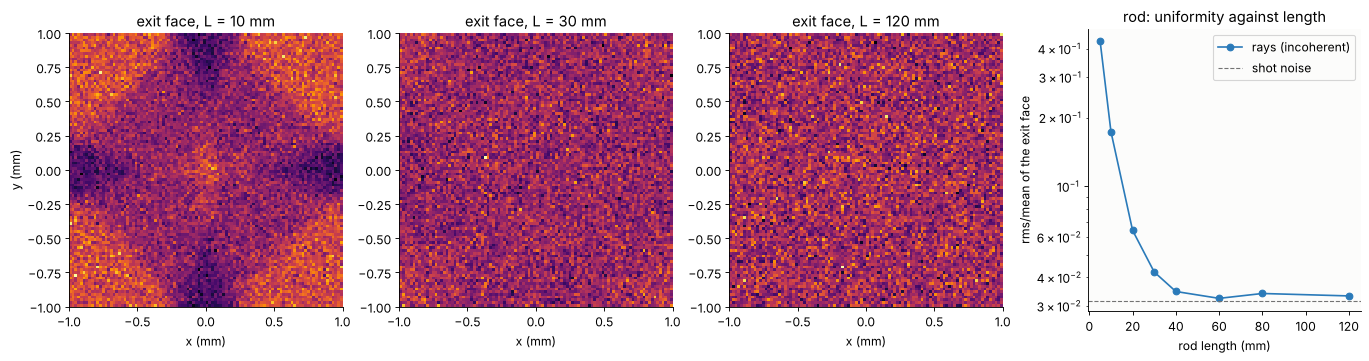

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(17, 4.4), layout="constrained")
for a, L in zip(ax[:3], (10, 30, 120)):
    Po = rod_maps[L]
    a.hist2d(Po[:, 0], Po[:, 1], bins=100, range=[(-1, 1)]*2, cmap="inferno")
    a.set_aspect("equal")
    a.set_title("exit face, L = {} mm".format(L))
    a.set_xlabel("x (mm)")
ax[0].set_ylabel("y (mm)")
ax[3].semilogy(lengths, rod_uni, "o-", color=BLUE, label="rays (incoherent)")
ax[3].axhline(1/np.sqrt(N5/400), color=GREY, ls="--", lw=1, label="shot noise")
ax[3].set_xlabel("rod length (mm)")
ax[3].set_ylabel("rms/mean of the exit face")
ax[3].set_title("rod: uniformity against length")
ax[3].legend()
plt.show()

A rod with three reflections per wall (30 mm) is close to the shot noise,
4.2 % against 3.2 %; at 40 mm and beyond the two agree. Shorter
rods show the pattern of the few virtual sources that overlap. At one
reflection (10 mm) the exit face has a dark cross where the direct and
the reflected light do not overlap. The rod needs no second element and
no condenser to make its field, and its exit face is a sharp-edged field
of its own. But it adds nothing to the étendue: the exit has the
entrance NA, and the directions form a comb, one per virtual source
(notebook 83).

With coherent light the virtual sources interfere like the channels of a
fly's eye. The exit field of a point source is the sum of the spherical
waves from its images, $\sum_m e^{ikr_m}/\sqrt{r_m}$ (2D), within the NA.
The fringes between neighbouring images have a period near
$\lambda L/(nW) = 10$ µm.

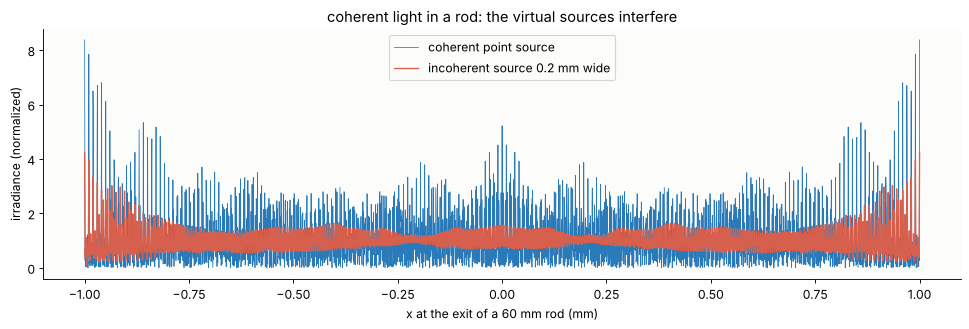

In [14]:
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(x5, I_rod/I_rod.mean(), color=BLUE, lw=0.7, label="coherent point source")
ax.plot(x5, I_rod_ext/I_rod_ext.mean(), color=RED, lw=1.2, label="incoherent source 0.2 mm wide")
ax.set_xlabel("x at the exit of a 60 mm rod (mm)")
ax.set_ylabel("irradiance (normalized)")
ax.set_title("coherent light in a rod: the virtual sources interfere")
ax.legend()
plt.show()

The coherent point source gives fringes with 80 % rms. A spatially
incoherent source 0.2 mm wide, as 41 mutually incoherent points, reduces
them to 24 %, for the same reason as in section 4. Each source point
shifts the fringes, and the shifted patterns add up to a smoother field.

## Summary

- **Fly's eye homogenizer:** every lenslet channel is imaged onto the
  same field of width $pF/f$, flat to the shot noise for a Gaussian and a
  ragged beam alike (`il.lenslet_array()`, `il.thin_lens()`).
- **Channels:** a smooth beam is evened out by a few lenslets, with an rms
  of $\sqrt 2\,e^{-2\pi^2\sigma^2/p^2}$. Fine structure averages as
  $1/\sqrt{N_\text{eff}}$, faster once the pitch nears its correlation
  length.
- **Imaging against non-imaging:** the second array makes the field
  independent of beam tilt and divergence up to $p/2f$; beyond that,
  crosstalk throws ghosts. A single array moves the field by $F\theta$ and
  blurs its edges by $F\sigma_\theta$.
- **Coherence:** coherent channels interfere into a comb with the period
  $\lambda F/p$ (`il.fly_eye_field_1d()`). An angular spread $\Delta\theta$
  scales its modulation by $|\operatorname{sinc}(\Delta\theta\,p/\lambda)|$,
  and it is gone at $\Delta\theta = \lambda/p$.
- **Integrator rod:** about three reflections per wall make the exit face
  even (`il.light_pipe()`). The rod conserves NA and étendue. With
  coherent light its virtual sources produce fringes, which an extended
  incoherent source reduces.

In [15]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 13 s


## References

- F. M. Dickey and S. C. Holswade (eds.), *Laser Beam Shaping: Theory and Techniques*, Marcel Dekker (2000), ch. 7 (lenslet array homogenizers).
- M. Zimmermann, N. Lindlein, R. Voelkel and K. J. Weible, "Microlens laser beam homogenizer: from theory to application", Proc. SPIE 6663, 666302 (2007).
- R. Voelkel and K. J. Weible, "Laser beam homogenizing: limitations and constraints", Proc. SPIE 7102, 71020J (2008).
- J. Chaves, *Introduction to Nonimaging Optics*, 2nd ed., CRC Press (2016), ch. 21 (Köhler integrators) and ch. 15 (light pipes).
- A. Büttner and U. D. Zeitner, "Wave optical analysis of light-emitting diode beam shaping using microlens arrays", Opt. Eng. 41, 2393-2401 (2002).
- C. M. Cassarly, "Nonimaging optics: concentration and illumination", in *Handbook of Optics*, 3rd ed., vol. II, McGraw-Hill (2010), ch. 39.